# 02 - Baselines: what must the LLM beat?

Before an LLM can claim to add value it has to beat simple, well-known methods on the **same data, same split and
same metrics**. This notebook builds those benchmarks.

| # | Baseline | Input it uses | Learns from data? | What it represents |
|---|---|---|---|---|
| 0 | Majority class | nothing | one number (class frequency) | "do nothing clever" floor |
| 1 | Loughran-McDonald lexicon | word counts | no | classic finance sentiment dictionary |
| 2 | TF-IDF + logistic regression | word / bigram weights | yes (supervised on returns) | classic machine learning on text |
| 3 | FinBERT | the whole sentence | pre-trained, not trained on our returns | finance-specific neural language model |

Each section explains the method, gives the maths, and ends with a check.

In [1]:
import sys; sys.path.append('..')
import re
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.offsets import BDay
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline

from src.baselines import load_lm_words, lexicon_score, finbert_scores
from src.evaluate import summarize_signal, daily_ic, daily_hits

SEED = 42
np.random.seed(SEED)
RAW, PROCESSED = Path('../data/raw'), Path('../data/processed')
pd.set_option('display.width', 200)

## 1. Load the dataset built in notebook 01

In [2]:
ds = pd.read_csv(PROCESSED / 'dataset.csv', parse_dates=['entry_date'])
ds['published_at'] = pd.to_datetime(ds['published_at'], utc=True)
ds['row_id'] = ds.index
need = {'published_at', 'ticker', 'headline', 'entry_date', 'abn_ret', 'label_up', 'time_known'}
assert need <= set(ds.columns), need - set(ds.columns)
assert ds['abn_ret'].notna().all() and ds['headline'].notna().all()
print(ds.shape, '| tickers:', ds['ticker'].nunique(), '| entry dates:', ds['entry_date'].min().date(), '->', ds['entry_date'].max().date())
display(ds.head(3))

(30000, 8) | tickers: 100 | entry dates: 2018-01-02 -> 2020-06-10


,published_at,ticker,headline,time_known,entry_date,abn_ret,label_up,row_id
0,2018-01-01 00:00:00+00:00,JD,Shanxi Securities Signs Agreement With Company...,False,2018-01-02,-0.001010,0,0
1,2018-01-01 00:00:00+00:00,KO,"Benzinga's Bulls & Bears: Apple, GE, Starbucks...",False,2018-01-02,-0.008520,0,1
2,2018-01-02 00:00:00+00:00,TGT,Bloomberg Gadfly Tweets: Is Amazon interested ...,False,2018-01-03,-0.023867,0,2


## 2. Train / test split by time

A random split is wrong here. Stocks and the market have regimes, and neighbouring days share information, so a random
split lets the model "see the future" through rows that sit next to its test rows. We always train on the **past** and
test on the **future**.

Let $e_i$ be the entry day of row $i$ and $c$ the cut-off date.

$$
\text{train} = \{\, i : e_i < c - h \,\}, \qquad \text{test} = \{\, i : e_i \ge c \,\}
$$

The gap $h$ (an **embargo**, here 2 business days) is dropped on purpose. A row's target is the return from the close of day
$e_i$ to the close of day $e_i+1$, so rows just before $c$ have targets that touch the first test days. The embargo
keeps those from leaking across the boundary (the idea of purging and embargoing comes from
López de Prado, *Advances in Financial Machine Learning*, 2018).

The cut-off is the date that leaves about 75% of the rows before it.

In [3]:
EMBARGO_DAYS = 2
cutoff = pd.Timestamp(ds['entry_date'].quantile(0.75)).normalize()
train_end = cutoff - BDay(EMBARGO_DAYS)

ds['split'] = np.where(ds['entry_date'] < train_end, 'train', np.where(ds['entry_date'] >= cutoff, 'test', 'embargo'))
print('cut-off:', cutoff.date(), '| train rows end before:', train_end.date())
split_tbl = ds.groupby('split').agg(rows=('row_id', 'size'), first_day=('entry_date', 'min'), last_day=('entry_date', 'max'),
                                    days=('entry_date', 'nunique'), share_up=('label_up', 'mean'))
display(split_tbl)

train, test = ds[ds['split'] == 'train'], ds[ds['split'] == 'test']
assert train['entry_date'].max() < test['entry_date'].min(), 'train and test overlap in time'
assert (test['entry_date'].min() - train['entry_date'].max()).days >= EMBARGO_DAYS, 'embargo not respected'
print('time order check passed | test headlines per day (median):', int(test.groupby('entry_date').size().median()))

cut-off: 2020-01-14 | train rows end before: 2020-01-10


,rows,first_day,last_day,days,share_up
split,,,,,
embargo,84,2020-01-10,2020-01-13,2,0.595238
test,7542,2020-01-14,2020-06-10,107,0.488199
train,22374,2018-01-02,2020-01-09,527,0.492402


time order check passed | test headlines per day (median): 72


### Check: is the test period a normal one?

Cross-sectional dispersion (the standard deviation of abnormal returns across stocks) by month. A much higher value in the
test period means a different market regime, and results measured there may not describe normal times.

median monthly dispersion  train: 0.0176   test: 0.0347
highest month: 2020-03 (0.0885)


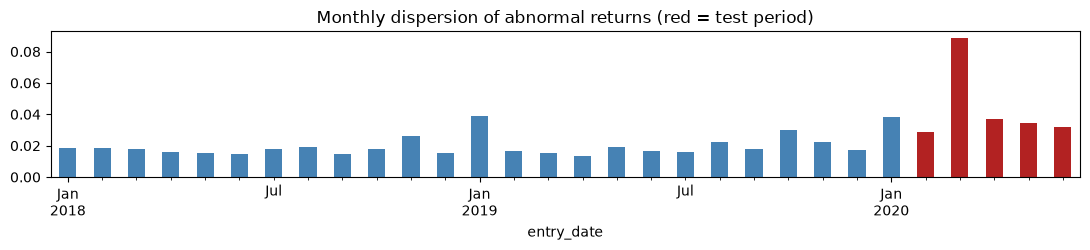

In [4]:
disp = ds.groupby(ds['entry_date'].dt.to_period('M'))['abn_ret'].std().rename('std of abnormal return')
disp_tbl = pd.DataFrame({'std of abnormal return': disp, 'in test': disp.index.map(lambda m: m.start_time >= cutoff)})
print(f'median monthly dispersion  train: {disp_tbl.loc[~disp_tbl["in test"], "std of abnormal return"].median():.4f}   test: {disp_tbl.loc[disp_tbl["in test"], "std of abnormal return"].median():.4f}')
print(f'highest month: {disp.idxmax()} ({disp.max():.4f})')
disp.plot.bar(figsize=(11, 2.6), color=['firebrick' if t else 'steelblue' for t in disp_tbl['in test']]); plt.title('Monthly dispersion of abnormal returns (red = test period)'); plt.tight_layout(); plt.show()

**Note.** The same 100 tickers appear in train and test, so we test generalisation **over time**, not to new companies.
A text model could in principle learn ticker-specific drift (e.g. "this company went up during the training period").
We look at the learned features in step 6 to see whether that happened.

## 3. Metrics, and a check that the metric code works

Let $s_i$ be a signal (a score where higher means "expect a better return") and $AR_i$ the abnormal return of row $i$.

**Direction accuracy** (neutral rows with $s_i = 0$ are skipped):

$$
\text{acc} = \frac{1}{n}\sum_i \mathbb{1}\big[\operatorname{sign}(s_i) = \operatorname{sign}(AR_i)\big]
$$

**Information Coefficient (IC)** is the Spearman rank correlation, i.e. the Pearson correlation of the ranks.
Without ties it equals

$$
\rho = 1 - \frac{6\sum_i d_i^2}{n(n^2-1)}, \qquad d_i = \operatorname{rank}(s_i) - \operatorname{rank}(AR_i).
$$

We report it in two ways. The **pooled IC** correlates all test rows at once. The **daily IC** ranks the stocks against each
other *within each entry day* $d$ and then averages over days:

$$
\overline{IC} = \frac{1}{D}\sum_{d=1}^{D} \rho_d, \qquad
t = \frac{\overline{IC}}{\operatorname{sd}(\rho_d)/\sqrt{D}}.
$$

The daily version is stricter, because stocks move together on a given day and rows from one day are not independent.
A common rule of thumb in quantitative practice is that a daily IC of roughly 0.02-0.05 is already useful; 0 means no
relationship.

**Confidence intervals** come from a *day-cluster bootstrap*: resample whole days with replacement and recompute the
statistic. That keeps the within-day dependence intact, so the interval is wider (more honest) than resampling single
headlines. It does not model dependence *between* days, so it is still somewhat optimistic.

### Check: does the metric code give the right answers on data where we know the truth?

Two fake signals on the real test set: pure noise (expected: accuracy near the base rate, IC near 0, interval containing 0)
and a weak signal built from the true return plus a lot of noise (expected: clearly positive IC).

In [5]:
rng = np.random.default_rng(SEED)
fake = test.copy()
fake['noise'] = rng.normal(size=len(fake))
fake['planted'] = fake['abn_ret'] / fake['abn_ret'].std() + rng.normal(scale=10, size=len(fake))   # weak planted signal

chk = pd.DataFrame({'pure noise': summarize_signal(fake, 'noise'), 'planted signal': summarize_signal(fake, 'planted')}).T
display(chk[['accuracy', 'acc_lo', 'acc_hi', 'mean_daily_ic', 'ic_lo', 'ic_hi', 'ic_t']].round(4))

assert abs(chk.loc['pure noise', 'mean_daily_ic']) < 0.03 and chk.loc['pure noise', 'ic_lo'] < 0 < chk.loc['pure noise', 'ic_hi'], 'noise should look like noise'
assert chk.loc['planted signal', 'ic_lo'] > 0, 'planted signal should be detected'
print('metric code behaves: noise -> IC ~ 0 with CI around 0, planted signal -> clearly positive IC')

,accuracy,acc_lo,acc_hi,mean_daily_ic,ic_lo,ic_hi,ic_t
pure noise,0.4972,0.486,0.5087,-0.0060,-0.0289,0.0173,-0.4963
planted signal,0.5286,0.519,0.5379,0.0647,0.0402,0.0897,5.1017


metric code behaves: noise -> IC ~ 0 with CI around 0, planted signal -> clearly positive IC


## 4. Baseline 0: majority class

Predict, for every test row, the class that was most common in the **training** set. It uses no text at all, so it tells us
what accuracy we get "for free" just from the base rate. Its accuracy is the share of that class in the test set:

$$
\hat y = \arg\max_k \; \hat P_{\text{train}}(y=k), \qquad \text{acc}_{\text{majority}} = P_{\text{test}}(y=\hat y).
$$

It has no IC (a constant score has no ranking).

In [6]:
majority_label = int(train['label_up'].mean() >= 0.5)
majority_acc = (test['label_up'] == majority_label).mean()
print(f'train share up = {train["label_up"].mean():.4f}  ->  majority class = {"up" if majority_label else "down"}')
print(f'test  share up = {test["label_up"].mean():.4f}  ->  majority-class accuracy on test = {majority_acc:.4f}')
print(f'(always-up would score {test["label_up"].mean():.4f}; notebook 01 found the full-sample majority accuracy was 0.5084)')

train share up = 0.4924  ->  majority class = down
test  share up = 0.4882  ->  majority-class accuracy on test = 0.5118
(always-up would score 0.4882; notebook 01 found the full-sample majority accuracy was 0.5084)


## 5. Baseline 1: Loughran-McDonald lexicon

**Idea.** Count positive and negative words from a dictionary and take the difference. General-purpose sentiment lists
(like Harvard IV) mislabel finance language: words such as *tax*, *cost*, *liability* or *capital* are everyday terms in
financial text, not negative sentiment. Loughran and McDonald built word lists from 10-K filings to fix that
(Loughran & McDonald, 2011, *When Is a Liability Not a Liability? Textual Analysis, Dictionaries, and 10-Ks*,
Journal of Finance 66(1), 35-65, doi:10.1111/j.1540-6261.2010.01625.x).

**Score** for a headline with $N$ words, $N_{+}$ positive and $N_{-}$ negative dictionary words:

$$
s^{\text{lex}} = \frac{N_{+} - N_{-}}{N}
$$

**What this implementation simplifies** relative to the paper: no tf-idf weighting of words, and no negation handling
(the paper treats "not good" differently from "good"). Headlines are short, so counts are tiny and the score is often
exactly 0. The word list file `data/raw/lm_pos_neg.csv` holds only the positive and negative words taken from the
Loughran-McDonald master dictionary (Notre Dame SRAF); it is git-ignored and should be cited when used.

In [7]:
pos_words, neg_words = load_lm_words(RAW / 'lm_pos_neg.csv')
print(f'{len(pos_words)} positive and {len(neg_words)} negative words')
assert (len(pos_words), len(neg_words)) == (354, 2355), 'word counts differ from the published LM 2011 lists'
assert not (pos_words & neg_words), 'a word is both positive and negative'

ds['lexicon'] = lexicon_score(ds['headline'], pos_words, neg_words)

# which dictionary words actually occur in our headlines?
pos_hits, neg_hits, matched = Counter(), Counter(), 0
for h in ds['headline']:
    toks = re.findall(r'[A-Za-z]+', h.upper())
    p = [t for t in toks if t in pos_words]; n = [t for t in toks if t in neg_words]
    pos_hits.update(p); neg_hits.update(n); matched += bool(p or n)
print(f'headlines with at least one dictionary word: {matched / len(ds):.1%} | with a non-zero score: {(ds["lexicon"] != 0).mean():.1%}')
print('most common positive words:', pos_hits.most_common(8))
print('most common negative words:', neg_hits.most_common(8))

354 positive and 2355 negative words


headlines with at least one dictionary word: 33.0% | with a non-zero score: 30.9%
most common positive words: [('OUTPERFORM', 583), ('POSITIVE', 502), ('STRONG', 357), ('BETTER', 301), ('STRENGTH', 233), ('DESPITE', 217), ('REBOUND', 195), ('BEST', 150)]
most common negative words: [('DOWNGRADES', 603), ('CONCERNS', 287), ('MISS', 232), ('CUT', 230), ('AGAINST', 219), ('WEAKNESS', 212), ('LATE', 161), ('FEARS', 152)]


In [8]:
# sanity: hand-written sentences must get the expected sign
probe = ['Strong gains and improved profitability', 'Weak sales, losses and a sharp decline', 'Company to hold annual meeting']
for text, s in zip(probe, lexicon_score(probe, pos_words, neg_words)):
    print(f'{s:+.3f}  {text}')
sp = lexicon_score(probe, pos_words, neg_words)
assert sp[0] > 0 and sp[1] < 0 and sp[2] == 0, 'lexicon signs are wrong on obvious sentences'

print('\nmost positive headlines:'); display(ds.nlargest(3, 'lexicon')[['ticker', 'headline', 'lexicon']])
print('most negative headlines:'); display(ds.nsmallest(3, 'lexicon')[['ticker', 'headline', 'lexicon']])

+0.800  Strong gains and improved profitability
-0.429  Weak sales, losses and a sharp decline
+0.000  Company to hold annual meeting

most positive headlines:


,ticker,headline,lexicon
506,PANW,Analyst: Palo Alto Now Has Better Opportunity ...,0.333333
9758,MDT,5 Best ETFs Of 2018,0.333333
15142,WFC,4 Of The Best Banking Reward Programs,0.333333


most negative headlines:


,ticker,headline,lexicon
20501,GOOGL,Alphabet Is Investigating Sexual Misconduct Al...,-0.500000
22393,XOM,ExxonMobil Wins Rare Challenge Against OFAC Pe...,-0.428571
10899,NVDA,Needham Downgrades NVIDIA to Underperform,-0.400000


## 6. Baseline 2: TF-IDF + logistic regression

**Idea.** Instead of a fixed dictionary, *learn* from the training data which words go with outperformance. This is the
standard supervised text baseline.

**Step 1, turn text into numbers with TF-IDF.** For term $t$ in document $d$, with $n$ documents and $\mathrm{df}(t)$
the number of documents containing $t$ (this is scikit-learn's smoothed form):

$$
x_{d,t} = \underbrace{\big(1 + \ln \mathrm{tf}(t,d)\big)}_{\text{sublinear term frequency}} \times
\underbrace{\Big(\ln\frac{1+n}{1+\mathrm{df}(t)} + 1\Big)}_{\text{inverse document frequency}}
$$

and each document vector is then scaled to unit length ($\ell_2$ norm). Words that appear everywhere (low IDF) get small
weights, rare and distinctive words get larger ones. We use single words and word pairs (1-2 grams) and ignore terms that
appear in fewer than 3 headlines.

**Step 2, logistic regression** predicts the probability of outperformance from the weight vector $\mathbf{x}$:

$$
P(y=1 \mid \mathbf{x}) = \sigma(\mathbf{w}^\top \mathbf{x} + b), \qquad \sigma(z) = \frac{1}{1+e^{-z}},
$$

fitted by minimising the regularised log-loss

$$
\min_{\mathbf{w},b}\; \frac{1}{2C}\lVert \mathbf{w}\rVert_2^2 \;-\; \sum_i \Big[ y_i \ln p_i + (1-y_i)\ln(1-p_i) \Big].
$$

A small $C$ means strong regularisation (simple model), a large $C$ lets the model fit the training data closely
and overfit. We choose $C$ with **time-ordered cross-validation** (each fold trains on earlier rows and validates on later
ones), scored by ROC-AUC, which does not depend on a decision threshold. The vectoriser sits **inside** the pipeline, so IDF
statistics are learned only from the training part of each fold (no leakage). The signal is $s^{\text{tfidf}} = P(y=1\mid\mathbf{x}) - 0.5$.

In [9]:
train = ds[ds['split'] == 'train'].sort_values('entry_date')      # time order matters for TimeSeriesSplit
pipe = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, lowercase=True)),
    ('lr', LogisticRegression(max_iter=1000)),
])
grid = GridSearchCV(pipe, {'lr__C': [0.01, 0.1, 1, 10]}, cv=TimeSeriesSplit(n_splits=3), scoring='roc_auc')
grid.fit(train['headline'], train['label_up'])

cvres = pd.DataFrame(grid.cv_results_)[['param_lr__C', 'mean_test_score', 'std_test_score']].round(4)
display(cvres)
print('best C:', grid.best_params_['lr__C'], '| cross-validated AUC:', round(grid.best_score_, 4), '(0.5 = no skill)')

train_auc = roc_auc_score(train['label_up'], grid.predict_proba(train['headline'])[:, 1])
print(f'in-sample AUC on the training rows: {train_auc:.4f}  -> the gap to the CV AUC shows how much the model memorises')

,param_lr__C,mean_test_score,std_test_score
0,0.01,0.5056,0.0054
1,0.10,0.5052,0.0063
2,1.00,0.5049,0.0078
3,10.00,0.5039,0.0073


best C: 0.01 | cross-validated AUC: 0.5056 (0.5 = no skill)


in-sample AUC on the training rows: 0.6702  -> the gap to the CV AUC shows how much the model memorises


In [10]:
model = grid.best_estimator_
test = ds[ds['split'] == 'test']
ds.loc[test.index, 'tfidf_lr'] = model.predict_proba(test['headline'])[:, 1] - 0.5

# what did it learn? If the top features are company names it is learning ticker-specific drift, not news content
names = model.named_steps['tfidf'].get_feature_names_out()
coef = model.named_steps['lr'].coef_[0]
order = np.argsort(coef)
print('features pushing toward DOWN:', list(names[order[:12]]))
print('features pushing toward UP  :', list(names[order[-12:]][::-1]))
print('vocabulary size:', len(names))

features pushing toward DOWN: ['maintains', 'on', 'ulta', 'beauty', 'mexican', 'alphabet', 'outlook', 'fy18', 'lowers price', 'lowers', 'on ulta', 'shares of']
features pushing toward UP  : ['oracle', 'cisco', 'in', 'nvidia', 'abbvie', 'more', 'of the', 'norfolk southern', 'norfolk', 'buy', 'says', 'and']
vocabulary size: 26027


Reading the feature lists: if many top features are company names or tickers, the model is partly learning *which company
did well during the training period*, which will not carry over. Words describing the news itself (upgrade, miss, guidance)
would be the evidence of real signal.

## 7. Baseline 3: FinBERT

**Idea.** A neural language model that already understands finance text, used as a fixed sentiment scorer.

- **BERT** (Devlin et al., 2019) is a Transformer encoder. It reads the whole sentence at once and builds a vector for each
  token that depends on all the other tokens, so "not good" is treated differently from "good" (a lexicon cannot do that).
- **FinBERT** (Araci, 2019, arXiv:1908.10063) starts from BERT, is further pre-trained on financial text, and is then
  fine-tuned to classify sentences as positive / negative / neutral on the Financial PhraseBank
  (Malo et al., 2014, JASIST 65(4), 782-796). We use the public checkpoint `ProsusAI/finbert`.
- The model outputs three raw scores (logits) $z_k$, turned into probabilities by the softmax:

$$
P_k = \frac{e^{z_k}}{\sum_j e^{z_j}}, \qquad k \in \{\text{positive},\ \text{negative},\ \text{neutral}\},
\qquad s^{\text{FinBERT}} = P_{\text{pos}} - P_{\text{neg}} \in [-1, 1].
$$

It is **not** trained on our returns. It only measures how positive the wording is, which is why it is a fair baseline for
the LLM (which will also read the wording). Scoring runs on CPU here; each unique headline is scored once and cached in
`data/processed/finbert_headline_scores.csv`, so re-running the notebook costs nothing.

In [11]:
CACHE = PROCESSED / 'finbert_headline_scores.csv'
sanity = pd.Series(['Company beats earnings estimates and raises full-year guidance',
                    'Company misses revenue estimates, shares plunge on weak outlook',
                    'Company to hold annual shareholder meeting on Tuesday'])

cached = pd.read_csv(CACHE) if CACHE.exists() else pd.DataFrame({'headline': [], 'finbert': []})
wanted = pd.concat([sanity, ds['headline']]).drop_duplicates()
todo = wanted[~wanted.isin(cached['headline'])]
print(f'unique headlines: {len(wanted):,} | already cached: {len(wanted) - len(todo):,} | to score now: {len(todo):,}')

if len(todo):
    new = pd.DataFrame({'headline': todo.tolist(), 'finbert': finbert_scores(todo.tolist(), batch_size=32)})
    cached = pd.concat([cached, new], ignore_index=True)
    cached.to_csv(CACHE, index=False)

lookup = cached.drop_duplicates('headline').set_index('headline')['finbert']
ds['finbert'] = ds['headline'].map(lookup)
assert ds['finbert'].notna().all(), 'some headlines have no FinBERT score'
assert ds['finbert'].between(-1, 1).all()
print('FinBERT scores attached to all', len(ds), 'rows')

unique headlines: 24,867 | already cached: 24,867 | to score now: 0
FinBERT scores attached to all 30000 rows


sanity sentences:
  +0.886  Company beats earnings estimates and raises full-year guidance
  -0.954  Company misses revenue estimates, shares plunge on weak outlook
  -0.012  Company to hold annual shareholder meeting on Tuesday

share of headlines with |score| < 0.1 (essentially neutral): 26.1%
score quantiles: {0.05: -0.959, 0.25: -0.359, 0.5: 0.045, 0.75: 0.649, 0.95: 0.921}


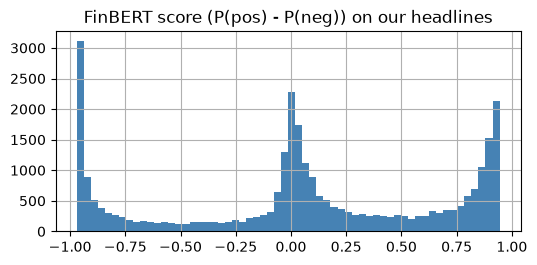

most positive:


,ticker,headline,finbert
7071,LLY,Leerink: Improving Fundamentals Drive Teva Upg...,0.944355
26080,TGT,Target Says Feb. 2020 Comparable Sales Increas...,0.944173
22858,CI,UPDATE: Amarin Spokesperson Tells Benzinga 'Va...,0.943744


most negative:


,ticker,headline,finbert
20682,EXPE,Expedia shares are trading lower. The stock dr...,-0.969160
11123,GILD,Gilead Sciences shares are trading lower after...,-0.968808
27735,TGT,Target shares are trading lower after the comp...,-0.968794


In [12]:
# sanity 1: obviously positive / negative / neutral sentences
print('sanity sentences:')
for s in sanity: print(f'  {lookup[s]:+.3f}  {s}')
assert lookup[sanity[0]] > 0.5 and lookup[sanity[1]] < -0.5 and abs(lookup[sanity[2]]) < 0.5

# sanity 2: distribution and extremes in OUR headlines
print(f'\nshare of headlines with |score| < 0.1 (essentially neutral): {(ds["finbert"].abs() < 0.1).mean():.1%}')
print('score quantiles:', ds['finbert'].quantile([.05, .25, .5, .75, .95]).round(3).to_dict())
ds['finbert'].hist(bins=60, figsize=(6, 2.6), color='steelblue'); plt.title('FinBERT score (P(pos) - P(neg)) on our headlines'); plt.show()
print('most positive:'); display(ds.nlargest(3, 'finbert')[['ticker', 'headline', 'finbert']])
print('most negative:'); display(ds.nsmallest(3, 'finbert')[['ticker', 'headline', 'finbert']])

## 8. Comparison on the test set

All signals are scored on the same test rows, with the same metrics. A signal is read as "up" when its score is above 0.

**How to read the table**

- `accuracy` should be compared with `majority_same_rows` (the majority-class accuracy on the same rows), not with 50%.
- `mean_daily_ic` is the headline number. If its interval contains 0, we cannot tell the signal from noise.
- `coverage` is the share of rows where the signal is not exactly neutral.

In [13]:
test = ds[ds['split'] == 'test']
signals = {'Lexicon (Loughran-McDonald)': 'lexicon', 'TF-IDF + logistic regression': 'tfidf_lr', 'FinBERT': 'finbert'}
res = pd.DataFrame({name: summarize_signal(test, col) for name, col in signals.items()}).T
# a signal is scored only on rows where it is not neutral, so compare it with the majority class on THOSE rows
res['majority_same_rows'] = [(test.loc[test[c] != 0, 'label_up'] == majority_label).mean() for c in signals.values()]
res.loc['Majority class'] = {'accuracy': majority_acc}

cols = ['coverage', 'accuracy', 'acc_lo', 'acc_hi', 'majority_same_rows', 'pooled_ic', 'mean_daily_ic', 'ic_lo', 'ic_hi', 'ic_t', 'n_days']
display(res[cols].astype(float).round(4))
print(f'test rows: {len(test):,} | test days: {test["entry_date"].nunique()} | majority-class accuracy to beat: {majority_acc:.4f}')

,coverage,accuracy,acc_lo,acc_hi,majority_same_rows,pooled_ic,mean_daily_ic,ic_lo,ic_hi,ic_t,n_days
Lexicon (Loughran-McDonald),0.3671,0.5172,0.4907,0.5427,0.5190,0.0263,0.0208,-0.0084,0.0505,1.3755,105.0
TF-IDF + logistic regression,1.0000,0.5093,0.4847,0.5338,0.5118,-0.0063,-0.0079,-0.0372,0.0239,-0.5038,106.0
FinBERT,1.0000,0.5034,0.4866,0.5198,0.5118,0.0111,0.0039,-0.0345,0.0421,0.2007,106.0
Majority class,NaN,0.5118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


test rows: 7,542 | test days: 107 | majority-class accuracy to beat: 0.5118


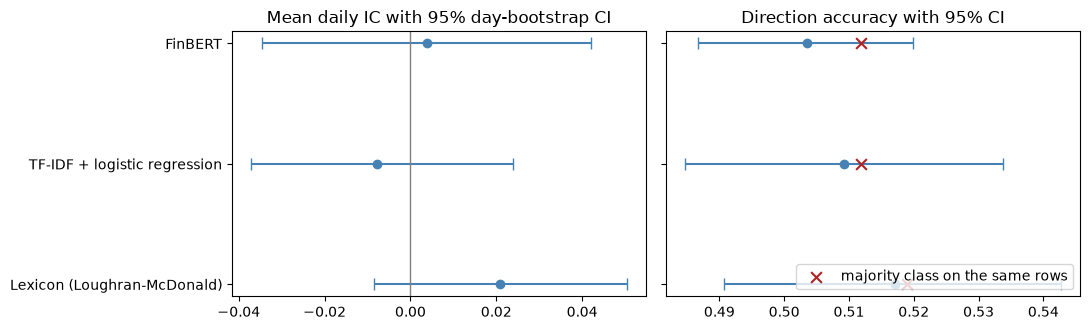

In [14]:
real = res.drop(index='Majority class').astype(float)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))

y = np.arange(len(real))
ax[0].errorbar(real['mean_daily_ic'], y, xerr=[real['mean_daily_ic'] - real['ic_lo'], real['ic_hi'] - real['mean_daily_ic']],
               fmt='o', color='steelblue', capsize=4)
ax[0].axvline(0, color='grey', lw=1); ax[0].set_yticks(y); ax[0].set_yticklabels(real.index)
ax[0].set_title('Mean daily IC with 95% day-bootstrap CI')

ax[1].errorbar(real['accuracy'], y, xerr=[real['accuracy'] - real['acc_lo'], real['acc_hi'] - real['accuracy']],
               fmt='o', color='steelblue', capsize=4)
ax[1].scatter(real['majority_same_rows'], y, marker='x', s=60, color='firebrick', zorder=3, label='majority class on the same rows')
ax[1].set_yticks(y); ax[1].set_yticklabels(['' for _ in y]); ax[1].legend(loc='lower right'); ax[1].set_title('Direction accuracy with 95% CI')
plt.tight_layout(); plt.show()

### Do the three signals at least agree with each other?

If the lexicon and FinBERT measured the same thing (wording positivity) they should be positively rank-correlated.
The TF-IDF model is trained on returns, not on sentiment, so a weak relationship with the other two is fine.

In [15]:
agree = test[['lexicon', 'finbert', 'tfidf_lr']].corr(method='spearman')
display(agree.round(3))
assert agree.loc['lexicon', 'finbert'] > 0, 'lexicon and FinBERT should agree on wording sentiment'

,lexicon,finbert,tfidf_lr
lexicon,1.000,0.479,-0.082
finbert,0.479,1.000,-0.041
tfidf_lr,-0.082,-0.041,1.000


## 9. Save the scores

`data/processed/baseline_scores.csv` is read by the later notebooks so the baselines are never recomputed.
TF-IDF scores exist only for test rows (training rows would be in-sample).

In [16]:
out = ds[['row_id', 'split', 'lexicon', 'finbert', 'tfidf_lr']]
out.to_csv(PROCESSED / 'baseline_scores.csv', index=False)
print('saved', PROCESSED / 'baseline_scores.csv', out.shape, '| tfidf_lr non-null:', out['tfidf_lr'].notna().sum())

saved ..\data\processed\baseline_scores.csv (30000, 5) | tfidf_lr non-null: 7542


## Takeaways (numbers copied from the outputs above)

**Setup.** Cut-off 2020-01-14. Train: 22,374 rows (527 days, 2018-01-02 to 2020-01-09). Test: 7,542 rows (107 days,
2020-01-14 to 2020-06-10). 84 rows fell in the 2-day embargo. The metric code passed its self-check (pure noise gave a
daily IC of -0.006 with an interval around 0; a planted weak signal gave +0.065 with an interval above 0).

**Results on the test set** (all intervals are 95% day-cluster bootstrap; "majority" = majority-class accuracy on the same rows):

| Signal | Coverage | Accuracy [CI] | Majority, same rows | Mean daily IC [CI] |
|---|---|---|---|---|
| Lexicon (Loughran-McDonald) | 36.7% | 51.72% [49.07, 54.27] | 51.90% | +0.021 [-0.008, +0.051] |
| TF-IDF + logistic regression | 100% | 50.93% [48.47, 53.38] | 51.18% | -0.008 [-0.037, +0.024] |
| FinBERT | 100% | 50.34% [48.66, 51.98] | 51.18% | +0.004 [-0.035, +0.042] |

**Reading it honestly**

1. **No baseline is distinguishable from chance.** Every IC interval contains 0 and no accuracy beats the majority class on
   the same rows. This was the expected outcome given the next-day entry rule from notebook 01, and it is the bar the LLM
   has to clear. If the LLM also lands here, that is the finding, not a failure.
2. **The methods behave as described.** Lexicon and FinBERT agree on wording sentiment (Spearman 0.48). FinBERT scores a clearly
   positive sentence +0.89, a clearly negative one -0.95, a neutral one -0.01, and about 26% of our headlines are near neutral.
3. **TF-IDF memorises.** Cross-validated AUC is 0.506 (no skill) but in-sample AUC is 0.670. Its strongest features are company
   names (ulta, oracle, cisco, nvidia, abbvie, alphabet, norfolk southern) and filler words, i.e. it learns which company
   drifted in the training period, not what the news says. Masking company names is worth trying, and it connects to the
   leakage check for the LLM.
4. **The lexicon makes visible mistakes.** For example "ExxonMobil Wins Rare Challenge Against OFAC ..." scores negative because
   of words like *challenge* and *against*. It has no negation or context handling.
5. **The test period is unusual.** Median monthly dispersion of abnormal returns is 3.47% in the test period against 1.76% in
   training, and March 2020 (COVID crash) reaches 8.85%. Conclusions from these 107 days may not carry over to normal markets.
6. **Low statistical power.** With 107 test days the daily-IC intervals are about +/-0.035 wide, so only a mean IC above roughly
   0.04 could be told apart from zero.

**Open decision for the LLM notebook.** A zero-shot LLM needs no training rows, so it could be scored on all 30,000 rows
(636 days, much more power, and it includes calmer markets) instead of only the 7,542 test rows. The cost is about four times
more API calls, which matters on a rate-limited free tier. Lexicon and FinBERT are also untrained, so they can be compared
on the same full sample; only TF-IDF needs the train/test split.